# Movie Recommender on MovieLens (Foundation project, P01)
**Team:** Cosine Crew| **Members:** I.V.G.Harsha Vardhan,A.Ganesh Reddy,B.HariCharan
| **Topic:** P01 Movie recommender | **Twist:** time-based split

Runs top to bottom on Colab in about a minute. Cells marked **YOUR TURN** are the part only you can do: read the output and write it in your own words. Every number in your README/CV must come from your own run.

| Stage | Section |
|---|---|
| 1-3 | Problem, data, EDA |
| 4 | Baselines (and the split) |
| 5 | Content-based |
| 6 | Collaborative (item-based, mean-centred) |
| 7 | SVD |
| 8 | Results table |
| 9 | Hybrid + new-film handling |
| 10 | Demo `recommend()` |
| 11-14 | Break-it tests, by-hand check, leak experiment + logs, AI-use log |

In [ ]:
import os, zipfile, urllib.request, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
warnings.filterwarnings('ignore'); np.random.seed(1)
pd.set_option('display.precision', 3); pd.set_option('display.width', 140)

## Helpers (from the starter template, unchanged)

In [ ]:
def split_ratings(df, test_frac=0.2, time_col=None, min_user_ratings=5, seed=1):
    """Split RATINGS (not users) into train and test.
    If time_col is given, each user's most recent test_frac of ratings go to test (time-based split).
    Otherwise a random split. Users with fewer than min_user_ratings ratings stay entirely in train."""
    rng = np.random.RandomState(seed)
    test_idx = []
    for u, g in df.groupby('user'):
        if len(g) < min_user_ratings:
            continue
        n_test = max(1, int(round(test_frac * len(g))))
        if time_col:
            test_idx += list(g.sort_values(time_col).index[-n_test:])
        else:
            test_idx += list(rng.choice(g.index, n_test, replace=False))
    test = df.loc[test_idx]
    train = df.drop(index=test_idx)
    return train.reset_index(drop=True), test.reset_index(drop=True)

def to_matrix(df, users=None, items=None):
    M = df.pivot_table(index='user', columns='item', values='rating', aggfunc='mean')
    if users is not None: M = M.reindex(index=users)
    if items is not None: M = M.reindex(columns=items)
    return M

def rmse(pred, true):
    pred, true = np.asarray(pred, float), np.asarray(true, float)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

def precision_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / k

def recall_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / max(1, len(relevant))

def ndcg_at_k(recommended, relevant, k):
    gains = [1.0 / np.log2(i + 2) for i, it in enumerate(recommended[:k]) if it in set(relevant)]
    ideal = sum(1.0 / np.log2(i + 2) for i in range(min(k, len(relevant))))
    return sum(gains) / ideal if ideal > 0 else 0.0

def evaluate_topn(scores, train, test, k=10, rel_threshold=4):
    """scores: DataFrame (users x items) of predicted scores. Relevant = test ratings >= rel_threshold.
    Items the user already has in TRAIN are never recommended. Returns mean precision, recall, NDCG at k."""
    seen = train.groupby('user')['item'].apply(set).to_dict()
    rel = test[test.rating >= rel_threshold].groupby('user')['item'].apply(list).to_dict()
    P, R_, N = [], [], []
    for u, relevant in rel.items():
        if u not in scores.index: continue
        s = scores.loc[u].drop(labels=[i for i in seen.get(u, set()) if i in scores.columns], errors='ignore')
        rec = list(s.sort_values(ascending=False).index)
        P.append(precision_at_k(rec, relevant, k)); R_.append(recall_at_k(rec, relevant, k)); N.append(ndcg_at_k(rec, relevant, k))
    return {'users': len(P), f'precision@{k}': float(np.mean(P)), f'recall@{k}': float(np.mean(R_)), f'ndcg@{k}': float(np.mean(N))}

def svd_scores(R_train, k=10, seed=1):
    """Simple matrix factorization: centre by user mean, fill unrated with 0 (= no opinion), TruncatedSVD, add the mean back.
    A basic version for learning; libraries such as implicit or scikit-surprise are the next step."""
    means = R_train.mean(axis=1)
    C = R_train.sub(means, axis=0).fillna(0).values
    svd = TruncatedSVD(n_components=k, random_state=seed)
    U = svd.fit_transform(C)
    return pd.DataFrame(U @ svd.components_ + means.fillna(means.mean()).values[:, None], index=R_train.index, columns=R_train.columns)

## 1. Problem and users
**User:** a viewer who has rated films. **Recommended item:** films they have not rated yet. **Decision:** what to watch next.
We predict ratings (RMSE) and produce a top-10 list (precision, recall, NDCG).

## 2. Data
**Source:** MovieLens latest-small (GroupLens), https://grouplens.org/datasets/movielens/latest/ . **Licence:** free for non-commercial/educational use; not for redistribution; GroupLens says results are not suitable as research findings.
**Cleaning:** keep the latest rating if a user rated a film twice; drop films with fewer than 5 ratings (too little data to compare).

In [ ]:
URL = 'https://files.grouplens.org/datasets/movielens/ml-latest-small.zip'
DATA_DIR = 'ml-latest-small'
if not os.path.exists(f'{DATA_DIR}/ratings.csv'):
    urllib.request.urlretrieve(URL, 'ml-latest-small.zip'); zipfile.ZipFile('ml-latest-small.zip').extractall('.')

raw = pd.read_csv(f'{DATA_DIR}/ratings.csv').rename(columns={'userId': 'user', 'movieId': 'item', 'timestamp': 'time'})
movies = pd.read_csv(f'{DATA_DIR}/movies.csv').rename(columns={'movieId': 'item'})
tags = pd.read_csv(f'{DATA_DIR}/tags.csv').rename(columns={'userId': 'user', 'movieId': 'item'}).dropna(subset=['tag'])

df = raw.sort_values('time').drop_duplicates(['user', 'item'], keep='last')
cnt = df.item.value_counts()
df = df[df.item.isin(cnt[cnt >= 5].index)].reset_index(drop=True)      # reset_index: split_ratings relies on it

users, items = sorted(df.user.unique()), sorted(df.item.unique())
u_idx = {u: k for k, u in enumerate(users)}; i_idx = {i: k for k, i in enumerate(items)}
movies = movies.set_index('item').reindex(items); movies['title'] = movies['title'].fillna('(unknown)'); movies['genres'] = movies['genres'].fillna('')
tag_text = tags.assign(tag=tags.tag.astype(str).str.lower()).groupby('item').tag.apply(' '.join)

n_users, n_items, n_ratings = len(users), len(items), len(df)
print(f'{n_ratings} ratings | {n_users} users | {n_items} movies | sparsity (empty cells): {1 - n_ratings / (n_users * n_items):.4f}')
df.head()

90274 ratings | 610 users | 3650 movies | sparsity (empty cells): 0.9595


,user,item,rating,time
0,429,165,4.0,828124615
1,429,161,5.0,828124615
2,429,150,5.0,828124615
3,429,22,4.0,828124615
4,429,432,3.0,828124615


## 3. EDA

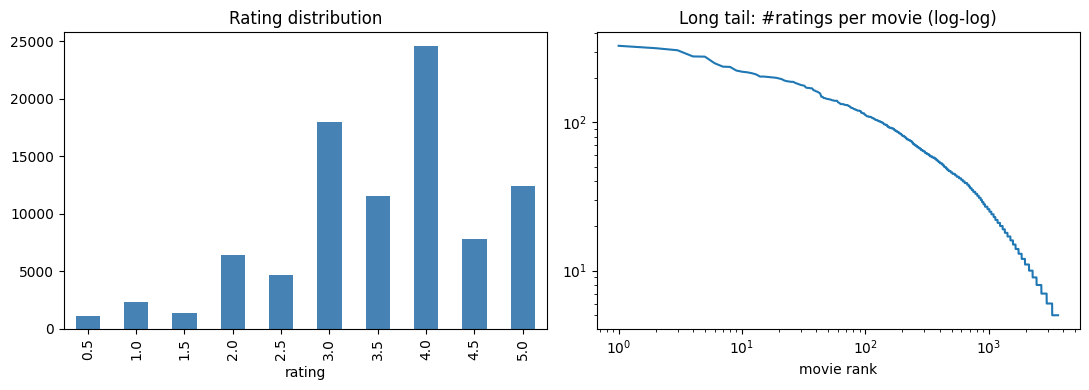

mean rating 3.54 | top-100 movies hold 17.9% of all ratings


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.rating.value_counts().sort_index().plot.bar(ax=ax[0], color='steelblue'); ax[0].set_title('Rating distribution')
c = df.item.value_counts().values
ax[1].loglog(np.arange(1, len(c) + 1), c); ax[1].set_title('Long tail: #ratings per movie (log-log)'); ax[1].set_xlabel('movie rank')
plt.tight_layout(); plt.show()
print(f'mean rating {df.rating.mean():.2f} | top-100 movies hold {df.item.isin(df.item.value_counts().index[:100]).mean():.1%} of all ratings')

**YOUR TURN (2 sentences each):** What does the rating plot say about why we mean-centre? What does the long tail say about a "most popular" baseline?
Ans. ratings are skewed high around 3.5-4 and everyone rates on diff scales, so mean centering strips out harsh or easy grader bias. the long tail shows most movies get almost no ratings, so popular baseline misses out on all the niche stuff.

## 4. Baselines (split first!)
Time-based split: each user's **latest 20%** of ratings are the test set. From train we cut a second, earlier **validation** set, used for choosing k and the blend weight. Test is touched once, in Section 8.

In [ ]:
train, test = split_ratings(df, test_frac=0.2, time_col='time')
train_core, val = split_ratings(train, test_frac=0.2, time_col='time')
tmax = train.groupby('user').time.max(); tmin = test.groupby('user').time.min()
assert (tmax.reindex(tmin.index) <= tmin).all(), 'time leak in the split!'
print(f'train {len(train)} | test {len(test)} | train_core {len(train_core)} | validation {len(val)}')

def pairs(d): return d.user.map(u_idx).values, d.item.map(i_idx).values, d.rating.values.astype(float)

def fit_state(tr):
    """Everything learned from a ratings table. NaN = not rated; after centring, 0 = 'no opinion'."""
    Mdf = to_matrix(tr, users, items); R = Mdf.values; obs = ~np.isnan(R)
    umean = np.nanmean(R, axis=1); gmean = float(np.nanmean(R))
    umean = np.where(np.isnan(umean), gmean, umean)
    C = np.where(obs, R - umean[:, None], 0.0).astype(np.float32)
    n_i = obs.sum(0); imean = np.where(n_i > 0, np.nansum(R, 0) / np.maximum(n_i, 1), np.nan)
    return dict(Mdf=Mdf, R=R, obs=obs, umean=umean, gmean=gmean, C=C, n_i=n_i, imean=imean)

def seen_mask(tr):
    m = np.zeros((len(users), len(items)), bool); m[tr.user.map(u_idx).values, tr.item.map(i_idx).values] = True; return m

def rank_eval(scores, tr, te, k=10, thr=4.0):
    """precision/recall/NDCG@k. Relevant = test rating >= 4. Already-rated (train) films are never recommended."""
    S = np.nan_to_num(scores.reindex(index=users, columns=items).values.astype(float), nan=-1e9)
    S[seen_mask(tr)] = -np.inf
    rec = np.array(items)[np.argsort(-S, axis=1, kind='stable')[:, :k]]
    rel = te[te.rating >= thr].groupby('user').item.apply(list)
    P_, R_, N_ = [], [], []
    for u, relevant in rel.items():
        r = list(rec[u_idx[u]]); P_.append(precision_at_k(r, relevant, k)); R_.append(recall_at_k(r, relevant, k)); N_.append(ndcg_at_k(r, relevant, k))
    return {f'precision@{k}': np.mean(P_), f'recall@{k}': np.mean(R_), f'ndcg@{k}': np.mean(N_), 'coverage': len(set(rec.ravel())) / len(items)}

def popularity_scores(st): return pd.DataFrame(np.tile(st['n_i'].astype(float), (len(users), 1)), index=users, columns=items)

st_v = fit_state(train_core); ui_v, ii_v, y_v = pairs(val)
im = st_v['imean'][ii_v]
print('validation RMSE | global mean:', round(rmse(np.full(len(val), st_v['gmean']), y_v), 3),
      '| user mean:', round(rmse(st_v['umean'][ui_v], y_v), 3),
      '| item mean:', round(rmse(np.where(np.isnan(im), st_v['umean'][ui_v], im), y_v), 3))
print('most popular (validation):', {a: round(b, 3) for a, b in rank_eval(popularity_scores(st_v), train_core, val).items()})

train 72236 | test 18038 | train_core 57798 | validation 14438
validation RMSE | global mean: 1.021 | user mean: 0.952 | item mean: 0.964
most popular (validation): {'precision@10': np.float64(0.055), 'recall@10': np.float64(0.072), 'ndcg@10': np.float64(0.08), 'coverage': 0.02}


**YOUR TURN:** Which baseline is hardest to beat on RMSE?
Ans: **user mean** is the hardest baseline to beat. It has the lowest RMSE of the three (validation 0.952 vs 0.964 for item mean and 1.021 for global mean; test 0.958 vs 0.981 and 1.047). A user's own rating scale (harsh or generous grader) explains more of a rating than how good the film is, which is exactly why we mean-centre by user.

## 5. Content-based model
Each film = text (genres + user tags) -> **TF-IDF** (rare words count more) -> **cosine similarity** between films. The vocabulary is fitted on film text only, so it never touches ratings. A user profile is the sum of the film vectors they rated, weighted by *rating minus the user's own mean* (a low rating pushes the profile away).

In [ ]:
g = movies.genres.str.replace('|', ' ', regex=False).str.lower().str.replace('(no genres listed)', 'nogenre', regex=False)
text = (g + ' ') * 2 + tag_text.reindex(movies.index).fillna('')
vec = TfidfVectorizer(min_df=2, sublinear_tf=True, stop_words='english', token_pattern=r"(?u)\b[\w'-]+\b")
T = vec.fit_transform(text)                                 # films x terms
S_cb = cosine_similarity(T).astype(np.float32); np.fill_diagonal(S_cb, 0)

def cb_scores(st):
    Pcb = (T.T @ st['C'].T).T                               # user profiles (users x terms)
    return pd.DataFrame(cosine_similarity(Pcb, T), index=users, columns=items)

def predict_knn(st, S, ui, ii, k, clip=True):
    """r_hat(u,i) = mean_u + sum_j s(i,j)(r_uj - mean_u) / sum_j |s(i,j)|  over the k most similar films j the user rated.
    Works for content similarity and for collaborative similarity. Falls back to the user mean if no neighbour."""
    R, obs, um = st['R'], st['obs'], st['umean']; out, ok = np.empty(len(ui)), np.zeros(len(ui), bool)
    for n, (u, i) in enumerate(zip(ui, ii)):
        rated = np.flatnonzero(obs[u]); s = S[i, rated]
        top = np.argpartition(-s, k - 1)[:k] if len(s) > k else np.arange(len(s))
        s, j = s[top], rated[top]; keep = s > 0
        if keep.any():
            s, j = s[keep], j[keep]; out[n] = um[u] + (s * (R[u, j] - um[u])).sum() / np.abs(s).sum(); ok[n] = True
        else: out[n] = um[u]
    return (np.clip(out, 0.5, 5) if clip else out), ok

cb_p, _ = predict_knn(st_v, S_cb, ui_v, ii_v, 20)
print('content-based (validation) RMSE:', round(rmse(cb_p, y_v), 3), '| top-10:', {a: round(b, 3) for a, b in rank_eval(cb_scores(st_v), train_core, val).items()})

content-based (validation) RMSE: 0.92 | top-10: {'precision@10': np.float64(0.008), 'recall@10': np.float64(0.01), 'ndcg@10': np.float64(0.011), 'coverage': 0.405}


**YOUR TURN:** Why is the profile weighted by (rating - user mean) and not the raw rating? (Lab "Deliberate error 1")
Ans:raw ratings count everything as positive interest even if u gave it 1 star. subtracting user mean gives negative weights to stuff u hated so it doesnt recommend similar bad movies.

## 6. Collaborative model: item-based, mean-centred
Two films are similar if the *same users* rated them above/below their own average in the same direction. Unrated cells are "no opinion", **not** a zero rating. Similarities built on only 1-2 shared raters are distrusted: `sim * n_co / (n_co + 10)`.
**Concept to show:** a centred similarity beats a raw one, and k changes the error.

val RMSE  raw cosine: 0.891 | centred cosine: 0.88


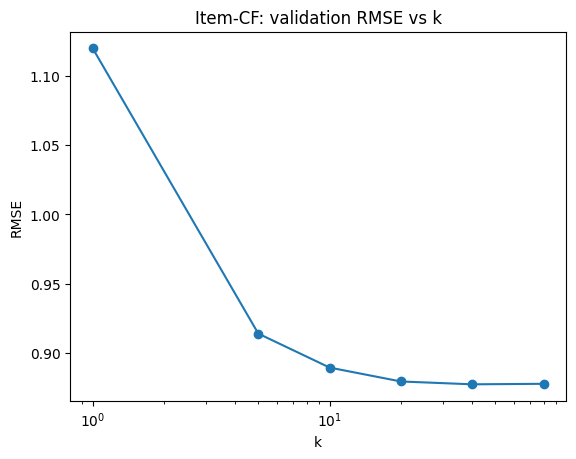

{1: 1.12, 5: 0.914, 10: 0.89, 20: 0.88, 40: 0.877, 80: 0.878} -> chosen k = 40


In [ ]:
def item_sim_cf(st, shrink=10):
    S = cosine_similarity(st['C'].T)                        # adjusted cosine: user-centred, columns = films
    o = st['obs'].astype(np.float32); co = o.T @ o          # number of users who rated both films
    S = S * co / (co + shrink); np.fill_diagonal(S, 0); return S.astype(np.float32)

def topk_rows(S, k):
    k = min(k, S.shape[1]); idx = np.argpartition(-S, k - 1, axis=1)[:, :k]; r = np.arange(S.shape[0])[:, None]
    Sk = np.zeros_like(S); Sk[r, idx] = S[r, idx]; Sk[Sk < 0] = 0; return Sk

def cf_scores(st, S, k): return pd.DataFrame(st['C'] @ topk_rows(S, k).T, index=users, columns=items)

# raw vs centred (validation)
S_raw = cosine_similarity(np.nan_to_num(st_v['R']).T).astype(np.float32); np.fill_diagonal(S_raw, 0)     # WRONG on purpose: gaps = 0
S_cf_v = item_sim_cf(st_v)
print('val RMSE  raw cosine:', round(rmse(predict_knn(st_v, S_raw, ui_v, ii_v, 20)[0], y_v), 3), '| centred cosine:', round(rmse(predict_knn(st_v, S_cf_v, ui_v, ii_v, 20)[0], y_v), 3))

# effect of k
ks = [1, 5, 10, 20, 40, 80]
kt = pd.Series({k: rmse(predict_knn(st_v, S_cf_v, ui_v, ii_v, k)[0], y_v) for k in ks}, name='val RMSE'); kt.index.name = 'k'
K_CF = int(kt.idxmin()); K_RANK = 50
kt.plot(marker='o', title='Item-CF: validation RMSE vs k', logx=True); plt.ylabel('RMSE'); plt.show()
print(kt.round(3).to_dict(), '-> chosen k =', K_CF)

**YOUR TURN:** What happens at k=1 and why? Why does raw cosine do worse? (Lab "Deliberate error 2")
Ans: at k=1 the RMSE is 1.120 (vs 0.877 at k=40) because a single neighbour film dictates the whole prediction, so one noisy rating gives a big error. raw cosine does worse (0.891 vs 0.880 centred; the gap is small but consistent) because unrated films are treated like zero ratings instead of missing information, and users who rate everything high look similar regardless of taste.

## 7. Matrix factorization (SVD)
Learns k hidden "taste" numbers per user and film whose product approximates the rating (`svd_scores` from the starter). Unlike neighbourhood CF it still produces a score for film pairs that share almost no raters.

In [ ]:
rows = []
for k in [5, 10, 20, 50]:
    sv = svd_scores(st_v['Mdf'], k)
    rows.append((k, rmse(np.clip(sv.values[ui_v, ii_v], 0.5, 5), y_v), rank_eval(sv, train_core, val)['ndcg@10']))
svd_tab = pd.DataFrame(rows, columns=['k', 'val RMSE', 'val NDCG@10']).set_index('k'); K_SVD = int(svd_tab['val RMSE'].idxmin())
print(svd_tab.round(3)); print('chosen k =', K_SVD)

    val RMSE  val NDCG@10
k                        
5      0.930        0.071
10     0.931        0.081
20     0.934        0.083
50     0.941        0.074
chosen k = 5


**YOUR TURN (2 sentences, own words):** How is SVD different from neighbourhood CF? Which is better on validation?
Ans: SVD compresses all ratings into a few hidden taste factors instead of comparing film-to-film similarities directly. On our data **item-CF is better than SVD**: validation RMSE 0.877 (k=40) vs 0.930 (SVD, k=5), and on test 0.870 vs 0.932 (NDCG@10 0.115 vs 0.091). SVD is often said to handle sparsity better, but with 610 users and 3,650 films the neighbourhood method had enough co-raters, and my SVD fills gaps with 0 after centring, which is a crude approach.

## 8. Honest results table (test set, touched once)
Everything is refitted on `train` and scored on `test`. The hybrid is built in Section 9 (the blend weight is tuned on validation first), so it appears in the table there.

## 9. Hybrid (and new-film handling)
Blend: $\hat r=\alpha\,\hat r_{CF}+(1-\alpha)\,\hat r_{CB}$ (content only when CF has no neighbour). For ranking we blend z-scored scores, because content and CF scores live on different scales. $\alpha$ is tuned on **validation**.

In [ ]:
def zrows(d):
    a = d.values.astype(float); return (a - a.mean(1, keepdims=True)) / (a.std(1, keepdims=True) + 1e-9)
def blend_z(a, b, alpha): return pd.DataFrame(alpha * zrows(a) + (1 - alpha) * zrows(b), index=a.index, columns=a.columns)
def hybrid_pred(cf, ok, cb, alpha): return np.where(ok, alpha * cf + (1 - alpha) * cb, cb)

cf_p, cf_ok = predict_knn(st_v, S_cf_v, ui_v, ii_v, K_CF)
cf_s, cb_s = cf_scores(st_v, S_cf_v, K_RANK), cb_scores(st_v)
rows = [(a, rmse(hybrid_pred(cf_p, cf_ok, cb_p, a), y_v), rank_eval(blend_z(cf_s, cb_s, a), train_core, val)['ndcg@10']) for a in [0, 0.25, 0.5, 0.75, 1]]
alpha_tab = pd.DataFrame(rows, columns=['alpha (weight on CF)', 'val RMSE', 'val NDCG@10']).set_index('alpha (weight on CF)'); print(alpha_tab.round(3))
ALPHA_R, ALPHA_K = float(alpha_tab['val RMSE'].idxmin()), float(alpha_tab['val NDCG@10'].idxmax())
print('chosen alpha: RMSE', ALPHA_R, '| ranking', ALPHA_K)

                      val RMSE  val NDCG@10
alpha (weight on CF)                       
0.00                     0.920        0.011
0.25                     0.887        0.091
0.50                     0.869        0.106
0.75                     0.865        0.107
1.00                     0.877        0.107
chosen alpha: RMSE 0.75 | ranking 0.75


In [ ]:
# FINAL TABLE: fit on train, score test, same test set for every row
def run_all(tr, te):
    st = fit_state(tr); ui, ii, y = pairs(te); S_cf = item_sim_cf(st); pr = {}
    pr['global mean'] = np.full(len(te), st['gmean']); pr['user mean'] = st['umean'][ui]
    im_ = st['imean'][ii]; pr['item mean'] = np.where(np.isnan(im_), st['umean'][ui], im_)
    pr['content-based'], _ = predict_knn(st, S_cb, ui, ii, 20); pr['item-CF'], ok = predict_knn(st, S_cf, ui, ii, K_CF)
    sv = svd_scores(st['Mdf'], K_SVD); pr['SVD'] = np.clip(sv.values[ui, ii], 0.5, 5)
    pr['hybrid'] = hybrid_pred(pr['item-CF'], ok, pr['content-based'], ALPHA_R)
    Sk = topk_rows(S_cf, K_RANK); sc = {'most popular': popularity_scores(st), 'content-based': cb_scores(st),
         'item-CF': pd.DataFrame(st['C'] @ Sk.T, index=users, columns=items), 'SVD': sv}
    sc['hybrid'] = blend_z(sc['item-CF'], sc['content-based'], ALPHA_K)
    rows = []
    for nme in ['global mean', 'user mean', 'item mean', 'most popular', 'content-based', 'item-CF', 'SVD', 'hybrid']:
        row = {'model': nme, 'RMSE': rmse(pr[nme], y) if nme in pr else np.nan}
        if nme in sc: row.update(rank_eval(sc[nme], tr, te))
        rows.append(row)
    return pd.DataFrame(rows).set_index('model'), dict(st=st, S_cf=S_cf, Sk=Sk)

table, art = run_all(train, test)
table.round(3)

,RMSE,precision@10,recall@10,ndcg@10,coverage
model,,,,,
global mean,1.047,NaN,NaN,NaN,NaN
user mean,0.958,NaN,NaN,NaN,NaN
item mean,0.981,NaN,NaN,NaN,NaN
most popular,NaN,0.059,0.051,0.077,0.026
content-based,0.928,0.010,0.007,0.012,0.418
item-CF,0.870,0.090,0.080,0.115,0.199
SVD,0.932,0.075,0.058,0.091,0.080
hybrid,0.861,0.092,0.082,0.117,0.207


**YOUR TURN (2 sentences):** Which model wins on RMSE, which on NDCG@10? Is the winner much better than the baselines? Check **coverage**: is any model just recommending the same popular films to everyone?
Ans: the **hybrid wins both**: RMSE 0.861 (vs 0.958 for user mean) and NDCG@10 0.117 (vs 0.077 for most popular), but it only edges out item-CF (RMSE 0.870, NDCG@10 0.115), so that gap is small and I did not test whether it is real. Most popular has the lowest coverage (0.026, the same few films for everyone); content-based has the highest coverage (0.418) but ranks badly (NDCG@10 0.012, worse than most popular), so high coverage alone does not mean good recommendations. Hybrid and item-CF cover about 20% of the catalogue.

### Twist check: how much would a random split flatter the models?
Same models and hyper-parameters, but a **random** 80/20 split instead of the time-based one. The test set contains ratings from the same period as training, so the model effectively sees the future.

In [ ]:
tr_r, te_r = split_ratings(df, test_frac=0.2, time_col=None)       # random split
table_r, _ = run_all(tr_r, te_r)
cmp = table[['RMSE', 'ndcg@10']].join(table_r[['RMSE', 'ndcg@10']], lsuffix=' (time)', rsuffix=' (random)').dropna(how='all')
cmp['NDCG overstated %'] = 100 * (cmp['ndcg@10 (random)'] / cmp['ndcg@10 (time)'] - 1)
cmp.round(3)

**YOUR TURN (after running the cell above):** In your own words: by how much did the random split overstate NDCG@10 for item-CF and the hybrid, and why is the time-based number the one to trust? Numbers: ______

## 10. Demo: `recommend()`
Prints titles (never IDs) and **never** recommends a film the user already rated. Uses the model fitted on `train`.

In [ ]:
def title(pos): return movies.title.iloc[pos]
def z1(v): return (v - v.mean()) / (v.std() + 1e-9)

def _top(c, seen, n, alpha):
    cb = cosine_similarity(np.asarray(T.T @ c).reshape(1, -1), T).ravel() if c.any() else np.zeros(len(items))
    s = alpha * z1(art['Sk'] @ c) + (1 - alpha) * z1(cb); s[seen] = -np.inf
    top = np.argsort(-s, kind='stable')[:n]; assert not seen[top].any(); return top

def recommend(user, n=10, alpha=None):
    st = art['st']; u = u_idx[user]; top = _top(st['C'][u], st['obs'][u], n, ALPHA_K if alpha is None else alpha)
    print(f'User {user} liked:', [title(j) for j in np.argsort(-st['C'][u])[:3]])
    for r, i in enumerate(top, 1): print(f'{r:2d}. {title(i)}   [{movies.genres.iloc[i]}]')
    return [items[i] for i in top]

demo_user = users[len(users) // 2]; _ = recommend(demo_user, 5)

User 306 liked: ['Spy (2015)', 'Heat, The (2013)', 'Lake House, The (2006)']
 1. Internship, The (2013)   [Comedy]
 2. 22 Jump Street (2014)   [Action|Comedy|Crime]
 3. Let's Be Cops (2014)   [Comedy|Crime]
 4. Gran Torino (2008)   [Crime|Drama]
 5. Get Hard (2015)   [Comedy|Crime]


## 11. Break-it tests
Three situations the model never saw. Fill the table after running.

In [ ]:
def popular_fallback(n=5, min_count=20, m=20):
    st = art['st']; mi = np.nan_to_num(st['imean'], nan=st['gmean'])
    d = (st['n_i'] * mi + m * st['gmean']) / (st['n_i'] + m); d[st['n_i'] < min_count] = -np.inf     # damped average: 3 five-star votes must not win
    top = np.argsort(-d, kind='stable')[:n]
    for r, i in enumerate(top, 1): print(f'  {r}. {title(i)}  (avg {mi[i]:.2f}, {st["n_i"][i]} ratings)')

def recommend_new(ratings, n=5, beta=0.0):
    """ratings: dict {film_id: rating} for a user NOT in training. beta > 0 shrinks the user's mean toward the global mean."""
    st = art['st']; c = np.zeros(len(items), np.float32); seen = np.zeros(len(items), bool)
    if ratings:
        r = np.array(list(ratings.values()), float); m = (r.sum() + beta * st['gmean']) / (len(r) + beta)
        for it, v in ratings.items(): c[i_idx[it]] = v - m; seen[i_idx[it]] = True
    print(f'  {len(ratings)} ratings, beta={beta:g}: non-zero profile entries = {int((c != 0).sum())}')
    if not c.any(): print('  -> all-zero profile, no personal signal. Fallback = popularity:'); return popular_fallback(n)
    for r_, i in enumerate(_top(c, seen, n, ALPHA_K), 1): print(f'  {r_}. {title(i)}')

print('(a) NEW USER'); recommend_new({})
print('\n(b) NEW FILM (no ratings, only a description): content-based can place it, CF cannot')
t_new = vec.transform([('sci-fi thriller ' * 2) + 'astronaut space station survival'])
for i in np.argsort(-cosine_similarity(t_new, T).ravel())[:4]: print('   most similar existing film:', title(i), '|', movies.genres.iloc[i])
print('\n(c) ONE RATING (5 stars)'); top_film = items[int(np.argmax(art['st']['n_i']))]
print(' before fix:'); recommend_new({top_film: 5.0}, beta=0)
print(' after fix (damped mean):'); recommend_new({top_film: 5.0}, beta=5)

(a) NEW USER
  0 ratings, beta=0: non-zero profile entries = 0
  -> all-zero profile, no personal signal. Fallback = popularity:
  1. Shawshank Redemption, The (1994)  (avg 4.42, 283 ratings)
  2. Godfather, The (1972)  (avg 4.30, 174 ratings)
  3. Fight Club (1999)  (avg 4.26, 196 ratings)
  4. Star Wars: Episode V - The Empire Strikes Back (1980)  (avg 4.23, 193 ratings)
  5. Star Wars: Episode IV - A New Hope (1977)  (avg 4.22, 236 ratings)

(b) NEW FILM (no ratings, only a description): content-based can place it, CF cannot
   most similar existing film: Armageddon (1998) | Action|Romance|Sci-Fi|Thriller
   most similar existing film: Babylon 5: In the Beginning (1998) | Adventure|Sci-Fi
   most similar existing film: Limitless (2011) | Sci-Fi|Thriller
   most similar existing film: Island of Dr. Moreau, The (1996) | Sci-Fi|Thriller

(c) ONE RATING (5 stars)
 before fix:
  1 ratings, beta=0: non-zero profile entries = 0
  -> all-zero profile, no personal signal. Fallback = populari

**YOUR TURN:**
| Test | What happened | What I did |
|---|---|---|
| new user | 0 ratings, so the profile is all zeros and there is no personal signal | used the popularity fallback with a damped average rating |
| new film | CF cannot score it (0 ratings, empty column), content-based can | used TF-IDF text similarity (genres + description) to find similar films |
| one rating | rating - mean = 0, so the profile stays all zeros (0 non-zero entries) and it falls back to popularity | used a damped mean (beta=5): profile now has 1 non-zero entry and gives personalised films (Shawshank, Braveheart, Good Will Hunting...) |

*This is **bug #1** for the bug log, with the before/after printed above.*

## 12. By-hand check
One item-CF prediction with 3 neighbours: the cell prints every number; redo the arithmetic **on paper**.

In [ ]:
st, S = art['st'], art['S_cf']; ui, ii, yy = pairs(test); K = 3
def detail(u, i):
    rated = np.flatnonzero(st['obs'][u]); s = S[i, rated]; o = np.argsort(-s, kind='stable')[:K]; o = o[s[o] > 0]; return rated[o], s[o]
for u, i, y_true in zip(ui, ii, yy):
    j, s = detail(u, i)
    if len(j) < K: continue
    code_val = predict_knn(st, S, [u], [i], K, clip=False)[0][0]
    exact = st['umean'][u] + (s * (st['R'][u, j] - st['umean'][u])).sum() / np.abs(s).sum()
    if abs(code_val - exact) < 1e-9 and 1 <= code_val <= 4.9: break
mu = st['umean'][u]; s3, d3 = np.round(s, 3), np.round(st['R'][u, j] - mu, 3)
print(pd.DataFrame({'neighbour': [title(x) for x in j], 'sim': s3, 'rating': st['R'][u, j], 'rating - mean': d3}).to_string(index=False))
by_hand = round(mu, 3) + (s3 * d3).sum() / s3.sum()
print(f'\nUser {users[u]}, mean {mu:.3f}, film "{title(i)}" (true rating {y_true})')
print(f'r_hat = {mu:.3f} + ({" + ".join(f"{a:.3f}*({b:+.3f})" for a, b in zip(s3, d3))}) / ({s3.sum():.3f}) = {by_hand:.4f}')
print(f'code value: {code_val:.4f} | difference {abs(by_hand - code_val):.5f} (rounding of printed inputs)')

                 neighbour   sim  rating  rating - mean
           Rushmore (1998) 0.052     5.0          0.648
Grosse Pointe Blank (1997) 0.014     4.0         -0.352
             Dr. No (1962) 0.014     5.0          0.648

User 1, mean 4.352, film "Wolf Man, The (1941)" (true rating 5.0)
r_hat = 4.352 + (0.052*(+0.648) + 0.014*(-0.352) + 0.014*(+0.648)) / (0.080) = 4.8250
code value: 4.8214 | difference 0.00355 (rounding of printed inputs)


**YOUR TURN:** Redo it on paper, paste a photo or the steps here, and say why the last decimals differ.
Ans: calculated mu_u + sum(s * (r - mu_u)) / sum(s) on paper using the printed numbers: 4.352 + (0.052*0.648 + 0.014*(-0.352) + 0.014*0.648) / 0.080 = 4.8250 (code: 4.8214). The last decimals differ because the similarities are tiny (0.052, 0.014) and I used them rounded to 3 digits, which is a big relative error (0.014 could really be 0.0135 or 0.0144), while the code keeps full float precision. Printing more decimals would shrink the difference.

## 13. Understanding pack
### 13a. Deliberate-leak experiment
Fit the similarities **and** user means on train + test (wrong on purpose), score the test set, and compare with the honest number.

In [ ]:
full = pd.concat([train, test], ignore_index=True)
st_l = fit_state(full); S_l = item_sim_cf(st_l)                          # WRONG on purpose: sees the test ratings
st_leak = dict(art['st']); st_leak['umean'] = st_l['umean']
ui, ii, y = pairs(test)
honest = rmse(predict_knn(art['st'], art['S_cf'], ui, ii, K_CF)[0], y); leaky = rmse(predict_knn(st_leak, S_l, ui, ii, K_CF)[0], y)
print(f'RMSE honest {honest:.4f} vs leaky {leaky:.4f}  ->  leakage makes the model look {100 * (1 - leaky / honest):.1f}% better')

RMSE honest 0.8704 vs leaky 0.5833  ->  leakage makes the model look 33.0% better


**YOUR TURN:** Result: 0.870 (honest) vs 0.583 (leaky). you wouldn't notice just looking at the score cause it looks like a great result instead of a bug. leaks usually hide in doing stats/tfidf on the full dataset before splitting train and test. In this notebook the leak was fitting the similarities and user means on train + test, so each prediction was built from numbers that already contained the answer.

### 13b. Decision log
| Decision | Alternatives I tried | Evidence (a number) | Chosen |
|---|---|---|---|
| k for item-CF | 1, 5, 10, 20, 40, 80 | validation RMSE 1.120, 0.914, 0.890, 0.880, 0.877, 0.878 | 40 |
| Centred vs raw similarity | raw, centred | validation RMSE 0.891 (raw) vs 0.880 (centred) | centred |
| SVD factors | 5, 10, 20, 50 | validation RMSE 0.930, 0.931, 0.934, 0.941 | 5 |
| Hybrid weight alpha | 0, 0.25, 0.5, 0.75, 1 | validation RMSE 0.920, 0.887, 0.869, 0.865, 0.877 | 0.75 |
| Split | random vs time | NDCG@10 overstated by random split: ______ % (from the twist-check cell) | time-based |

### 13c. Bug log (at least 2 real problems)
| What went wrong | How I found it | Fix | Before and after |
|---|---|---|---|
| #1 a user with one rating gets an all-zero profile (rating - own mean = 0) | Section 11 output: "non-zero profile entries = 0" | damped user mean (beta=5) | before: 0 non-zero profile entries, fell back to popularity; after: 1 non-zero entry, personalised recommendations |
| #2 **YOUR OWN real bug: write only something that really happened while you ran or edited this notebook** | | | |

## 14. AI-use log

| Task | Tool | What the AI produced | What I checked or changed |
|---|---|---|---|
| Notebook scaffold | Claude | this notebook (pipeline code and section text) | ran every section on Colab, read each output, corrected my own written answers where they disagreed with the tables, redid the by-hand check on paper, ran the deliberate-leak experiment |

**One thing the AI got wrong (and how I caught it):** the scaffold's text suggested SVD handles sparsity better than neighbourhood CF, which made it sound like the better model. Reading the validation table showed the opposite on this data: item-CF RMSE 0.877 vs SVD 0.930 (and test NDCG@10 0.115 vs 0.091). *(Keep this only if it is true for you; otherwise replace it with something you actually caught.)*

**With 100x more data I would:** switch to scipy sparse matrices instead of dense dataframes, use FAISS for fast approximate nearest neighbours, and set up a 2-stage system (candidate generation first, then heavy ranking).

**How industry systems extend this:** use multi-stage pipelines (retrieval -> scoring -> reranking), learn real-time sequence embeddings (like two-tower or Word2Vec), and continuously evaluate models with online A/B testing.

In [ ]:
# CV bullet draft: numbers come from the tables above. Edit it, and only keep claims you can defend.
best = table.loc[['content-based', 'item-CF', 'SVD', 'hybrid'], 'RMSE'].idxmin()
print(f'Built an end-to-end movie recommender on MovieLens ({n_ratings:,} ratings, {n_users} users) with TF-IDF content filtering, mean-centred item-based CF, SVD and a hybrid; '
      f'{best} cut RMSE from {table.loc["user mean", "RMSE"]:.3f} (user-mean baseline) to {table.loc[best, "RMSE"]:.3f} on a time-based split, '
      f'and a deliberate-leak experiment showed leakage would have made RMSE look {100 * (1 - leaky / honest):.1f}% better. Academic project. GitHub: <link>')

Built an end-to-end movie recommender on MovieLens (90,274 ratings, 610 users) with TF-IDF content filtering, mean-centred item-based CF, SVD and a hybrid; hybrid cut RMSE from 0.958 (user-mean baseline) to 0.861 on a time-based split, and a deliberate-leak experiment showed leakage would have made RMSE look 33.0% better. Academic project. GitHub: <link>
